# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import dataset

In [2]:
dataset = pd.read_csv("Ads_CTR_Optimisation.csv")

# Importing Thompson Sampling

In [3]:
import random
N = 10000
d = 10
ads_selected = []
numbers_of_rewards_1 = [0] * d
numbers_of_rewards_0 = [0] * d
total_reward = 0
for n in range(0, N):
  ad = 0
  max_random = 0
  for i in range(0, d):
    random_beta = random.betavariate(numbers_of_rewards_1[i] + 1, numbers_of_rewards_0[i] + 1)
    if (random_beta > max_random):
      max_random = random_beta
      ad = i
  ads_selected.append(ad)
  reward = dataset.values[n, ad]
  if reward == 1:
    numbers_of_rewards_1[ad] = numbers_of_rewards_1[ad] + 1
  else:
    numbers_of_rewards_0[ad] = numbers_of_rewards_0[ad] + 1
  total_reward = total_reward + reward

# Thompson Sampling Code Explanation (Line by Line)


---

# Step 1

```python
import random
```

## What does this do?

Imports Python's **random module**.

Unlike UCB,

which required

```python
import math
```

Thompson Sampling requires

```python
import random
```

because it generates **random probabilities**.

---

# Step 2

```python
N = 10000
```

## What is N?

`N` represents the **total number of users (rounds).**

The dataset contains

```text
10000 rows
```

Each row represents one user.

```text
Round 1 → User 1

Round 2 → User 2

Round 3 → User 3

...

Round 10000 → User 10000
```

---

# Step 3

```python
d = 10
```

## What is d?

`d` represents the **number of advertisements.**

```text
Ad0

Ad1

Ad2

...

Ad9
```

There are **10 advertisements**.

---

# Step 4

```python
ads_selected = []
```

## Purpose

Stores

> **Which advertisement was selected in every round.**

Initially

```python
[]
```

Suppose

Round 1

Advertisement 4 selected

```python
[4]
```

Round 2

Advertisement 2 selected

```python
[4,2]
```

Round 3

Advertisement 4 selected again

```python
[4,2,4]
```

This list is later used for plotting the histogram.

---

# Step 5

```python
numbers_of_rewards_1 = [0] * d
```

## Purpose

Stores

> **Number of Successes (Clicks)**

Initially

```text
Ad0 Ad1 Ad2 Ad3 Ad4 Ad5 Ad6 Ad7 Ad8 Ad9

 0   0   0   0   0   0   0   0   0   0
```

Suppose

Advertisement 4 gets clicked.

Reward

```text
1
```

Now

```text
0 0 0 0 1 0 0 0 0 0
```

Later

Advertisement 4 gets another click

```text
0 0 0 0 2 0 0 0 0 0
```

This array stores

```text
Total Clicks
```

---

# Step 6

```python
numbers_of_rewards_0 = [0] * d
```

## Purpose

Stores

> **Number of Failures (No Clicks)**

Initially

```text
0 0 0 0 0 0 0 0 0 0
```

Suppose

Advertisement 4 is shown

User does not click

Reward

```text
0
```

Now

```text
0 0 0 0 1 0 0 0 0 0
```

Meaning

Advertisement 4 has failed once.

---

# Important Difference from UCB

UCB stores

```text
Number of Selections

Total Rewards
```

Thompson Sampling stores

```text
Number of Successes

Number of Failures
```

---

# Step 7

```python
total_reward = 0
```

## Purpose

Stores

> **Total number of clicks received from all advertisements.**

Initially

```text
0
```

Later

```text
1

2

3

...

5500
```

---

# Main Loop

```python
for n in range(0, N):
```

## Purpose

Runs

```text
10000 times
```

Each iteration means

```text
One new user arrives.
```

---

# Initially

```python
ad = 0
```

Temporarily assume

```text
Advertisement 0
```

is selected.

Later another advertisement may replace it.

---

# Store Largest Random Probability

```python
max_random = 0
```

Initially

```text
Largest Random Probability = 0
```

As random values are generated,

this variable keeps track of the highest one.

---

# Check Every Advertisement

```python
for i in range(0, d):
```

Checks every advertisement.

```text
Ad0

Ad1

Ad2

...

Ad9
```

One by one.

---

# The Most Important Line

```python
random_beta = random.betavariate(
    numbers_of_rewards_1[i] + 1,
    numbers_of_rewards_0[i] + 1
)
```

## What is `random.betavariate()`?

Think of it as a machine.

It takes

```text
Number of Successes

Number of Failures
```

and returns

```text
One Random Probability
```

---

### Example 1

Advertisement 4

```text
Clicks = 8

Failures = 2
```

Python executes

```python
random.betavariate(9,3)
```

Notice

```text
8 + 1

2 + 1
```

Suppose it returns

```text
0.84
```

---

### Example 2

Advertisement 2

```text
Clicks = 3

Failures = 7
```

Python executes

```python
random.betavariate(4,8)
```

Suppose it returns

```text
0.41
```

---

### Example 3

Advertisement 9

```text
Clicks = 15

Failures = 5
```

Python executes

```python
random.betavariate(16,6)
```

Suppose it returns

```text
0.78
```

Now we have

| Advertisement | Random Probability |
|---------------|--------------------|
| Ad0 | 0.33 |
| Ad1 | 0.62 |
| Ad2 | 0.41 |
| Ad3 | 0.71 |
| Ad4 | 0.84 |
| Ad5 | 0.39 |

Highest probability

```text
0.84
```

Therefore

```text
Advertisement 4 is selected.
```

---

# Why +1?

Suppose initially

```text
Successes = 0

Failures = 0
```

If we write

```python
random.betavariate(0,0)
```

Python cannot generate a Beta Distribution because both parameters must be **greater than zero**.

Instead we write

```python
random.betavariate(1,1)
```

This creates a

> **Uniform Beta Distribution**

Meaning

```text
Initially,

every probability between

0 and 1

is equally likely.
```

No advertisement is preferred initially.

As more clicks and failures are collected,

the Beta Distribution changes automatically.

---

# Compare Random Probabilities

```python
if (random_beta > max_random):
```

Suppose

| Advertisement | Random Probability |
|---------------|--------------------|
| Ad0 | 0.45 |
| Ad1 | 0.81 |
| Ad2 | 0.67 |

Initially

```text
Maximum Random Probability = 0
```

Advertisement 0

```text
0.45 > 0
```

True

Store

```text
Maximum = 0.45

Selected Advertisement = Ad0
```

Advertisement 1

```text
0.81 > 0.45
```

True

Store

```text
Maximum = 0.81

Selected Advertisement = Ad1
```

Advertisement 2

```text
0.67 > 0.81
```

False

Ignore.

Finally

```text
Advertisement 1
```

is selected.

---

# Store Largest Random Probability

```python
max_random = random_beta
ad = i
```

Stores

- Largest random probability
- Corresponding advertisement index

At the end of the loop,

`ad`

contains the advertisement having the highest sampled probability.

---

# Save Selected Advertisement

```python
ads_selected.append(ad)
```

Suppose

Advertisement 4 is selected.

Initially

```python
[]
```

After Round 1

```python
[4]
```

After Round 2

Advertisement 7

```python
[4,7]
```

---

# Read Reward from Dataset

```python
reward = dataset.values[n, ad]
```

Suppose

Current user

```text
25
```

Selected advertisement

```text
Ad4
```

Python reads

```python
dataset.values[25,4]
```

If value is

```text
1
```

User clicked.

Reward

```text
1
```

If value is

```text
0
```

User did not click.

Reward

```text
0
```

---

# If User Clicks

```python
if reward == 1:
```

Suppose

Reward

```text
1
```

Meaning

The user clicked.

Update

```python
numbers_of_rewards_1[ad] += 1
```

Example

Before

```text
Advertisement 4

Successes = 5
```

After

```text
Successes = 6
```

---

# Otherwise (No Click)

```python
else:
```

If reward is

```text
0
```

The user did not click.

Increase failures.

```python
numbers_of_rewards_0[ad] += 1
```

Example

Before

```text
Failures = 12
```

After

```text
Failures = 13
```

---

# Update Total Reward

```python
total_reward = total_reward + reward
```

Suppose

Current Total Reward

```text
3560
```

Current Reward

```text
1
```

Now

```text
3561
```

If reward is

```text
0
```

The total reward remains unchanged.

---

# Complete Working of Thompson Sampling

```text
New User Arrives
        │
        ▼
For Every Advertisement
        │
        ▼
Generate One Random Probability
Using Beta Distribution
        │
        ▼
Choose Advertisement
With Highest Random Probability
        │
        ▼
Show Advertisement
        │
        ▼
Read Reward From Dataset
        │
        ├──────────────┐
        │              │
        ▼              ▼
Reward = 1       Reward = 0
Success++        Failure++
        │
        ▼
Update Total Reward
        │
        ▼
Next User Arrives
```

---

# UCB vs Thompson Sampling Code

| UCB | Thompson Sampling |
|------|-------------------|
| Stores **Number of Selections** and **Total Rewards** | Stores **Successes** and **Failures** |
| Calculates `Average Reward + Confidence Interval` | Generates one random probability using `random.betavariate()` |
| Uses `math.sqrt()` and `math.log()` | Uses `random.betavariate()` |
| Deterministic | Probabilistic |
| Selects advertisement with highest UCB | Selects advertisement with highest sampled probability |

---

# Most Important Line to Remember

```python
random_beta = random.betavariate(successes + 1, failures + 1)
```

### Meaning

> **Based on the number of clicks and failures an advertisement has received, generate one random estimate of its click probability.**

Then

> **Choose the advertisement having the highest estimated probability.**

# Visualising the results

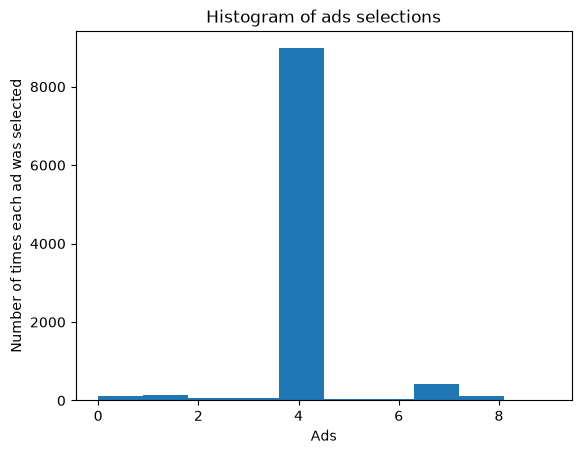

In [4]:
plt.hist(ads_selected)
plt.title('Histogram of ads selections')
plt.xlabel('Ads')
plt.ylabel('Number of times each ad was selected')
plt.show()